In [1]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns
import warnings 
warnings.filterwarnings('ignore')

In [2]:
df=pd.read_csv('loan_data.csv')

In [3]:
df.head()

,person_age,person_gender,person_education,person_income,person_emp_exp,person_home_ownership,loan_amnt,loan_intent,loan_int_rate,loan_percent_income,cb_person_cred_hist_length,credit_score,previous_loan_defaults_on_file,loan_status
0,22.0,female,Master,71948.0,0,RENT,35000.0,PERSONAL,16.02,0.49,3.0,561,No,1
1,21.0,female,High School,12282.0,0,OWN,1000.0,EDUCATION,11.14,0.08,2.0,504,Yes,0
2,25.0,female,High School,12438.0,3,MORTGAGE,5500.0,MEDICAL,12.87,0.44,3.0,635,No,1
3,23.0,female,Bachelor,79753.0,0,RENT,35000.0,MEDICAL,15.23,0.44,2.0,675,No,1
4,24.0,male,Master,66135.0,1,RENT,35000.0,MEDICAL,14.27,0.53,4.0,586,No,1


In [4]:
df.isnull().sum()

person_age                        0
person_gender                     0
person_education                  0
person_income                     0
person_emp_exp                    0
person_home_ownership             0
loan_amnt                         0
loan_intent                       0
loan_int_rate                     0
loan_percent_income               0
cb_person_cred_hist_length        0
credit_score                      0
previous_loan_defaults_on_file    0
loan_status                       0
dtype: int64

In [5]:
num_col=['person_age','person_income','loan_amnt','loan_int_rate','loan_percent_income','cb_person_cred_hist_length']

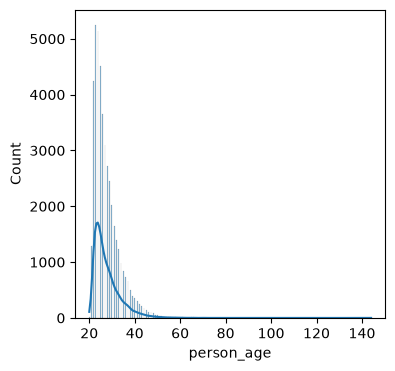

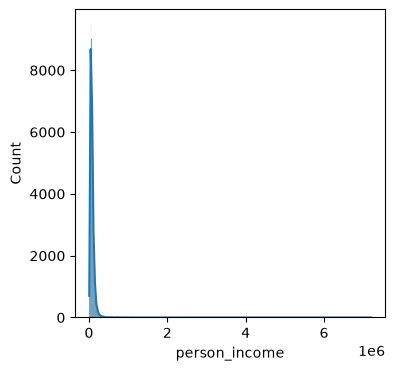

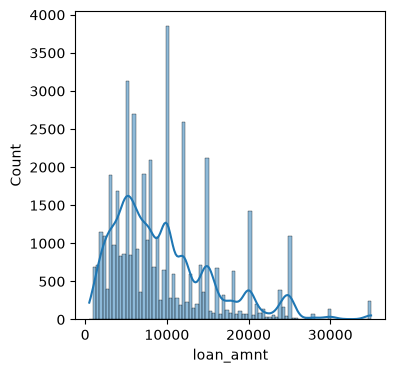

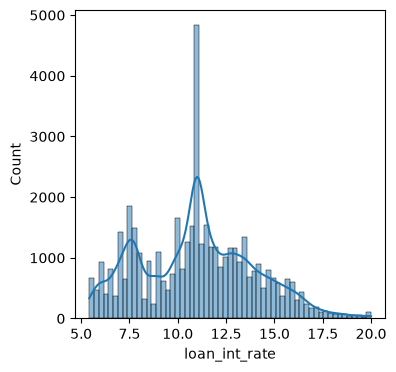

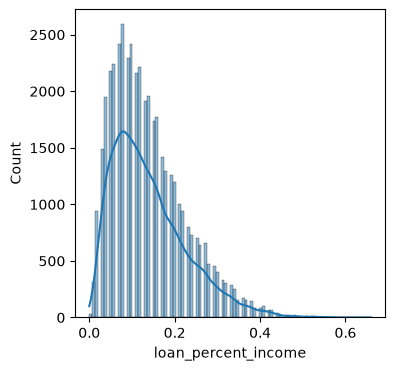

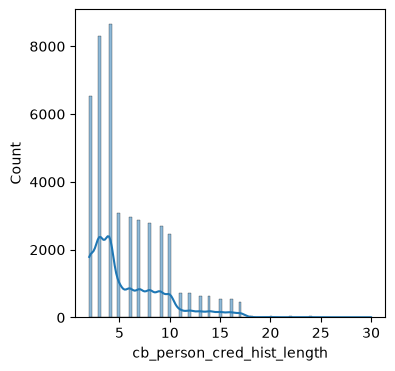

In [6]:
for col in num_col:
    plt.figure(figsize=(4,4))
    sns.histplot(df[col],kde=True)

In [7]:
cat_col = [
    col for col in df.columns
    if col not in num_col and col != 'loan_status'
]


In [8]:
cat_col

['person_gender',
 'person_education',
 'person_emp_exp',
 'person_home_ownership',
 'loan_intent',
 'credit_score',
 'previous_loan_defaults_on_file']

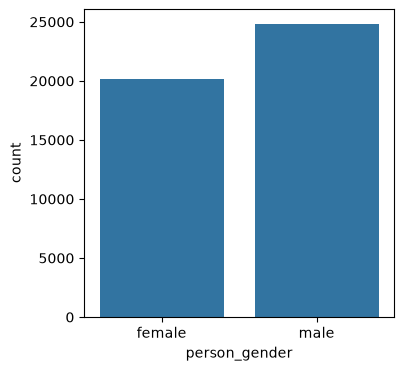

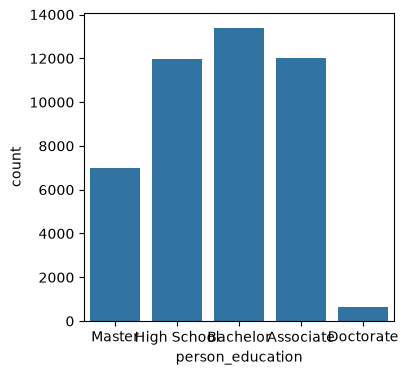

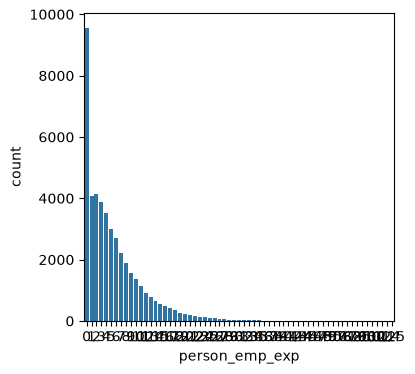

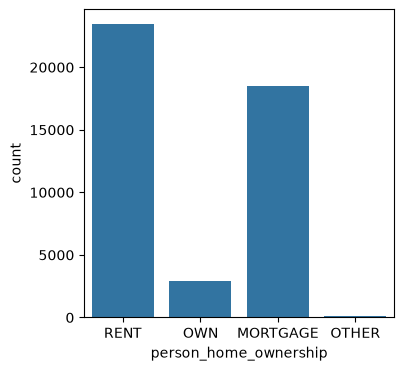

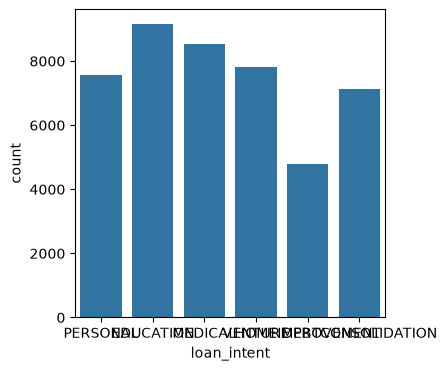

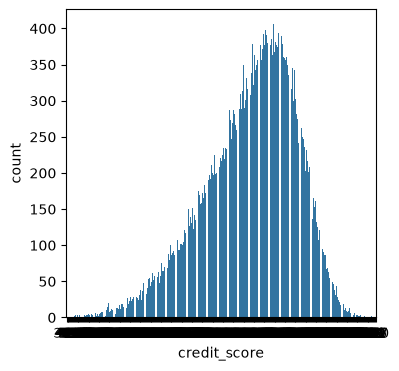

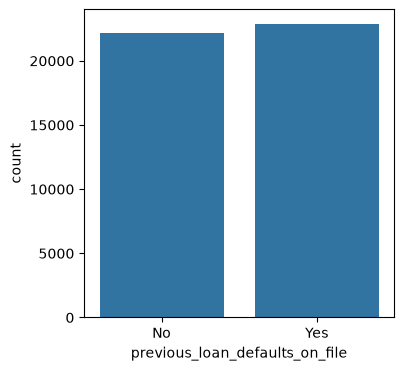

In [9]:
for col in cat_col:
    plt.figure(figsize=(4, 4))
    sns.countplot(data=df, x=col)


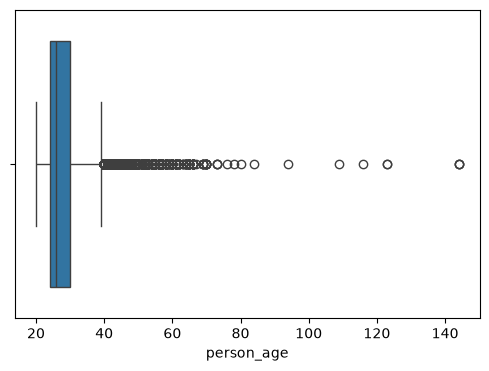

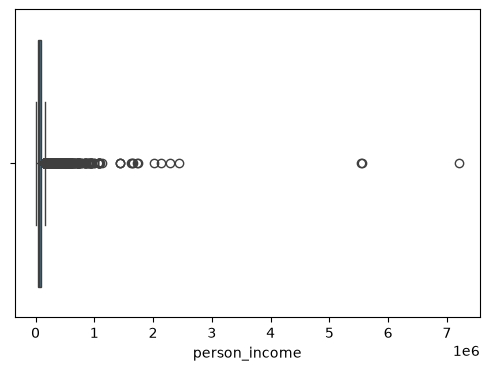

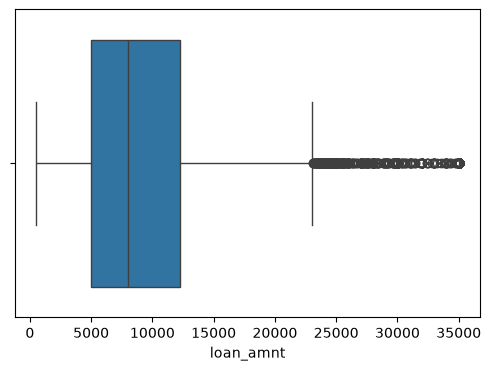

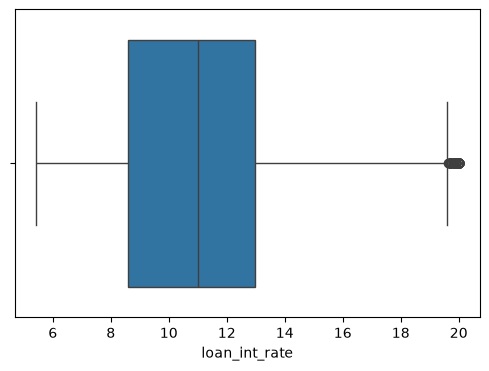

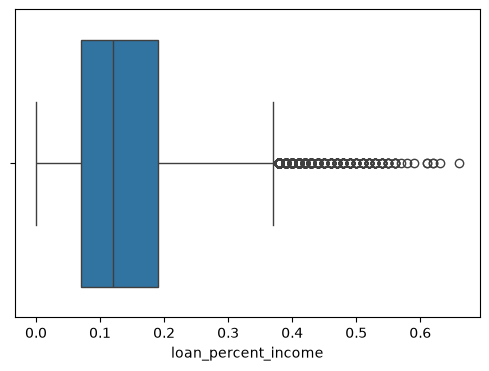

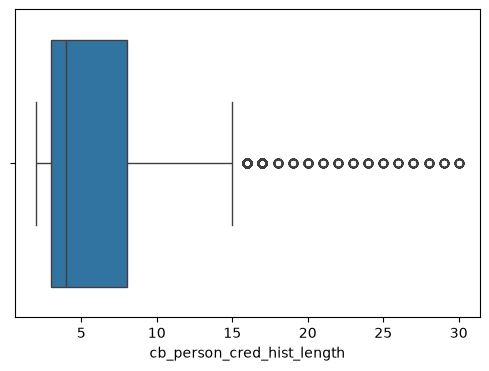

In [10]:
for col in num_col:
    plt.figure(figsize= (6,4))
    sns.boxplot(x = df[col])

In [11]:
df.loc[df['person_age'] > 100, 'person_age'] = np.nan

In [12]:
df['person_age']=df['person_age'].fillna(df['person_age'].mean())

In [13]:
df.loc[df['person_emp_exp']>80,'person_emp_exp']=np.nan
df['person_emp_exp']=df['person_emp_exp'].fillna(df['person_emp_exp'].mean())

<Axes: >

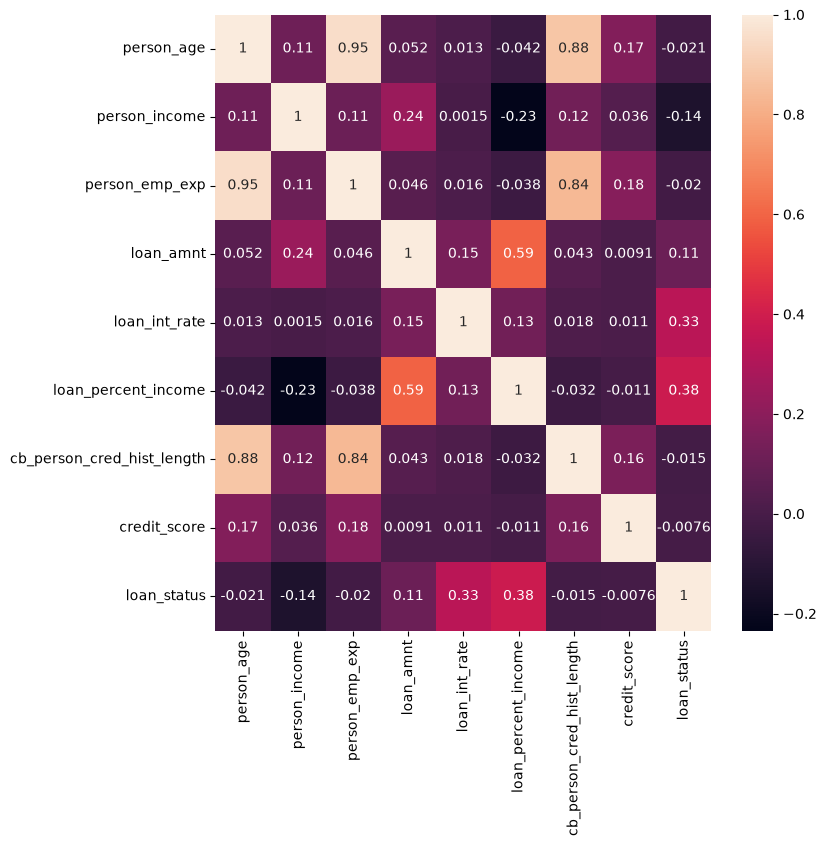

In [14]:
plt.figure(figsize=(8,8))
sns.heatmap(df.corr(numeric_only=True),annot=True)

In [15]:
df=df.drop(columns=['credit_score'])
df.drop(columns=['person_emp_exp'],inplace=True)
df.columns


Index(['person_age', 'person_gender', 'person_education', 'person_income',
       'person_home_ownership', 'loan_amnt', 'loan_intent', 'loan_int_rate',
       'loan_percent_income', 'cb_person_cred_hist_length',
       'previous_loan_defaults_on_file', 'loan_status'],
      dtype='str')

In [16]:
copy_df=df.copy()
copy_df.head()


,person_age,person_gender,person_education,person_income,person_home_ownership,loan_amnt,loan_intent,loan_int_rate,loan_percent_income,cb_person_cred_hist_length,previous_loan_defaults_on_file,loan_status
0,22.0,female,Master,71948.0,RENT,35000.0,PERSONAL,16.02,0.49,3.0,No,1
1,21.0,female,High School,12282.0,OWN,1000.0,EDUCATION,11.14,0.08,2.0,Yes,0
2,25.0,female,High School,12438.0,MORTGAGE,5500.0,MEDICAL,12.87,0.44,3.0,No,1
3,23.0,female,Bachelor,79753.0,RENT,35000.0,MEDICAL,15.23,0.44,2.0,No,1
4,24.0,male,Master,66135.0,RENT,35000.0,MEDICAL,14.27,0.53,4.0,No,1


In [19]:
cat_col = [
    col for col in df.columns
    if col not in num_col and col != 'loan_status'
]

In [20]:
cat_col

['person_gender',
 'person_education',
 'person_home_ownership',
 'loan_intent',
 'previous_loan_defaults_on_file']

In [21]:
num_col

['person_age',
 'person_income',
 'loan_amnt',
 'loan_int_rate',
 'loan_percent_income',
 'cb_person_cred_hist_length']

In [22]:
copy_df = pd.get_dummies(df, columns=cat_col, dtype=int)

copy_df.head()

,person_age,person_income,loan_amnt,loan_int_rate,loan_percent_income,cb_person_cred_hist_length,loan_status,person_gender_female,person_gender_male,person_education_Associate,...,person_home_ownership_OWN,person_home_ownership_RENT,loan_intent_DEBTCONSOLIDATION,loan_intent_EDUCATION,loan_intent_HOMEIMPROVEMENT,loan_intent_MEDICAL,loan_intent_PERSONAL,loan_intent_VENTURE,previous_loan_defaults_on_file_No,previous_loan_defaults_on_file_Yes
0,22.0,71948.0,35000.0,16.02,0.49,3.0,1,1,0,0,...,0,1,0,0,0,0,1,0,1,0
1,21.0,12282.0,1000.0,11.14,0.08,2.0,0,1,0,0,...,1,0,0,1,0,0,0,0,0,1
2,25.0,12438.0,5500.0,12.87,0.44,3.0,1,1,0,0,...,0,0,0,0,0,1,0,0,1,0
3,23.0,79753.0,35000.0,15.23,0.44,2.0,1,1,0,0,...,0,1,0,0,0,1,0,0,1,0
4,24.0,66135.0,35000.0,14.27,0.53,4.0,1,0,1,0,...,0,1,0,0,0,1,0,0,1,0


In [23]:
from scipy.stats import pearsonr

correlations = {
    feature: pearsonr(copy_df[feature], copy_df['loan_status'])[0]
    for feature in num_col
}
correlation_df = pd.DataFrame(list(correlations.items()), columns=['Feature', 'Pearson Correlation'])
correlation_df.sort_values(by='Pearson Correlation', ascending=False)

,Feature,Pearson Correlation
4,loan_percent_income,0.384880
3,loan_int_rate,0.332005
2,loan_amnt,0.107714
5,cb_person_cred_hist_length,-0.014851
0,person_age,-0.020545
1,person_income,-0.135808


In [25]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score,f1_score,classification_report
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB 
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier 
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier

In [30]:
X = copy_df.drop(columns=['loan_status'])
y=copy_df['loan_status']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

In [31]:
scaler=StandardScaler()


In [34]:

X_train_scaled=scaler.fit_transform(X_train)
X_test_scaled=scaler.fit_transform(X_test)

In [50]:
models={
    "logistic Regression ":LogisticRegression(),
    "Knn":KNeighborsClassifier(),
    "Naive bayes" : GaussianNB(),
    "Decision Tree" : DecisionTreeClassifier(),
    "Svm":SVC()
}


In [58]:
Result=[]

In [59]:
for name,model in models.items():
    model.fit(X_train_scaled,y_train)
    y_pred=model.predict(X_test_scaled)
    acc=accuracy_score(y_test,y_pred)
    f1_sc=f1_score(y_test,y_pred)
    
    Result.append({
        'model':name,
        'Accuracy':round(acc,4),
        "F1_score":round(f1_sc,4)
    
    })

In [60]:
Result

[{'model': 'logistic Regression ', 'Accuracy': 0.8902, 'F1_score': 0.7504},
 {'model': 'Knn', 'Accuracy': 0.8943, 'F1_score': 0.7479},
 {'model': 'Naive bayes', 'Accuracy': 0.7767, 'F1_score': 0.0},
 {'model': 'Decision Tree', 'Accuracy': 0.8821, 'F1_score': 0.7522},
 {'model': 'Svm', 'Accuracy': 0.9122, 'F1_score': 0.7919}]

In [48]:
Res=[]

In [61]:
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix

Result = []

for name, model in models.items():
    model.fit(X_train_scaled, y_train)

    y_pred = model.predict(X_test_scaled)

    acc = accuracy_score(y_test, y_pred)
    f1_sc = f1_score(y_test, y_pred)
    cm = confusion_matrix(y_test, y_pred)

    Res.append({
        'model': name,
        'Accuracy': round(acc, 4),
        'F1_score': round(f1_sc, 4),
        'Confusion_Matrix': cm.tolist()
    })

print(Res)

[{'model': 'logistic Regression ', 'Accuracy': 0.8902, 'F1_score': 0.7504, 'Confusion_Matrix': [[6527, 463], [525, 1485]]}, {'model': 'Knn', 'Accuracy': 0.8943, 'F1_score': 0.7479, 'Confusion_Matrix': [[6638, 352], [599, 1411]]}, {'model': 'Naive bayes', 'Accuracy': 0.7767, 'F1_score': 0.0, 'Confusion_Matrix': [[6990, 0], [2010, 0]]}, {'model': 'Decision Tree', 'Accuracy': 0.8821, 'F1_score': 0.7515, 'Confusion_Matrix': [[6335, 655], [406, 1604]]}, {'model': 'Svm', 'Accuracy': 0.9122, 'F1_score': 0.7919, 'Confusion_Matrix': [[6707, 283], [507, 1503]]}]


In [62]:
import joblib 
joblib.dump(models['Svm'],"Svm_Loan_model.pkl")
joblib.dump(scaler,"Scaler_Loan_model.pkl")
joblib.dump(X.columns.to_list(),"Columns_Loan_model.pkl")

['Columns_Loan_model.pkl']